**HAM10000** (Human Against Machine with 10,000 training images) is a publicly available dermatoscopic image dataset containing 10,015 images of pigmented skin lesions across seven diagnostic categories. The dataset includes diagnostic labels and additional metadata such as lesion identifiers, patient age, sex, anatomical localization, and diagnosis confirmation method.

The dataset is particularly useful for studying imbalanced medical image classification because its diagnostic categories have substantially different representation.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from PIL import Image
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")

PROJECT_ROOT = Path.cwd()
DATA_DIR = PROJECT_ROOT / "data" / "raw"

df = pd.read_csv(DATA_DIR / "HAM10000_metadata")

print(f"Total images: {len(df):,}")
print(f"Unique lesions: {df['lesion_id'].nunique():,}")
print(f"Diagnostic categories: {df['dx'].nunique()}")
print(f"Metadata features: {len(df.columns)}")

display(df.head())

Total images: 10,015
Unique lesions: 7,470
Diagnostic categories: 7
Metadata features: 8


,lesion_id,image_id,dx,dx_type,age,sex,localization,dataset
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,vidir_modern
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,vidir_modern
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,vidir_modern
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,vidir_modern
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,vidir_modern


In [5]:
class_counts = df["dx"].value_counts().sort_values(ascending=False)
class_percentages = df["dx"].value_counts(normalize=True) * 100

distribution = pd.DataFrame({
    "Images": class_counts,
    "Percentage (%)": class_percentages
})

display(distribution.round(2))

,Images,Percentage (%)
dx,,
nv,6705,66.95
mel,1113,11.11
bkl,1099,10.97
bcc,514,5.13
akiec,327,3.27
vasc,142,1.42
df,115,1.15


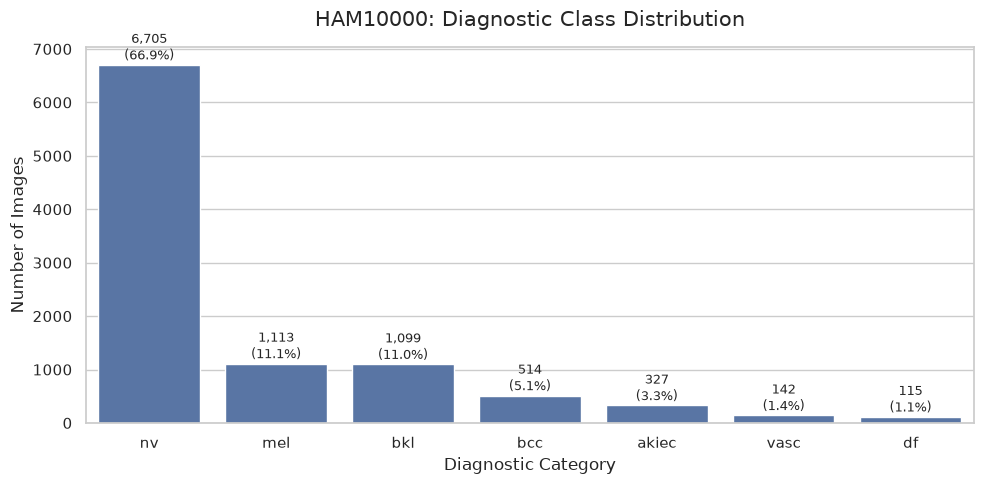

In [6]:
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

plt.title("HAM10000: Diagnostic Class Distribution",
          fontsize=15, pad=15)
plt.xlabel("Diagnostic Category")
plt.ylabel("Number of Images")

for i, value in enumerate(class_counts.values):
    percentage = class_percentages[class_counts.index[i]]
    ax.text(
        i, value + 100,
        f"{value:,}\n({percentage:.1f}%)",
        ha="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [7]:
imbalance_ratio = class_counts.max() / class_counts.min()

print(f"Majority class: {class_counts.idxmax().upper()}")
print(f"Minority class: {class_counts.idxmin().upper()}")
print(f"Imbalance ratio: {imbalance_ratio:.2f}:1")


Majority class: NV
Minority class: DF
Imbalance ratio: 58.30:1


In [8]:
images_per_lesion = df.groupby("lesion_id").size()

multiplicity = (
    images_per_lesion
    .value_counts()
    .sort_index()
)

print("Images per lesion:")
display(multiplicity.rename("Number of lesions").to_frame())

Images per lesion:


,Number of lesions
1,5514
2,1423
3,490
4,34
5,5
6,4


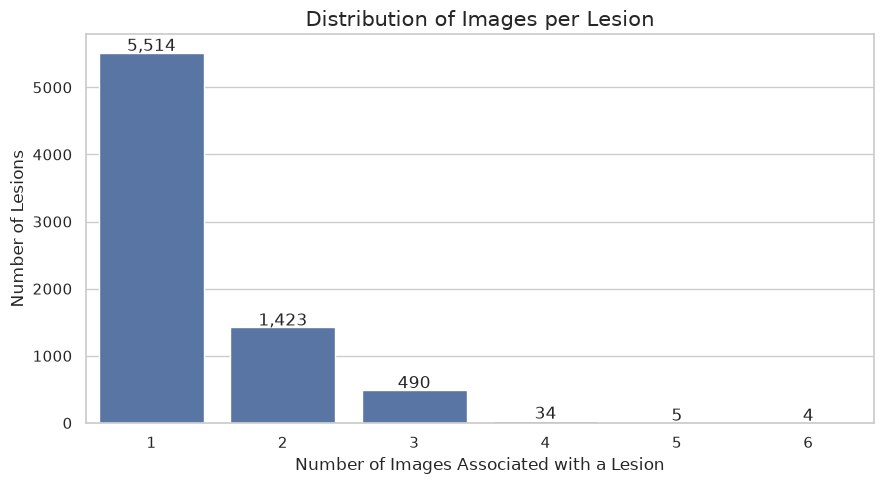

In [9]:
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=multiplicity.index,
    y=multiplicity.values
)

plt.title("Distribution of Images per Lesion", fontsize=15)
plt.xlabel("Number of Images Associated with a Lesion")
plt.ylabel("Number of Lesions")

for i, value in enumerate(multiplicity.values):
    ax.text(i, value + 30, f"{value:,}", ha="center")

plt.tight_layout()
plt.show()

In [10]:
diagnoses_per_lesion = df.groupby("lesion_id")["dx"].nunique()

inconsistent_lesions = diagnoses_per_lesion[
    diagnoses_per_lesion > 1
]

print("Lesions with inconsistent diagnostic labels:",
      len(inconsistent_lesions))

Lesions with inconsistent diagnostic labels: 0


In [11]:
lesion_data = (
    df[["lesion_id", "dx"]]
    .drop_duplicates("lesion_id")
)

image_counts = df["dx"].value_counts()
lesion_counts = lesion_data["dx"].value_counts()

comparison = pd.DataFrame({
    "Image count": image_counts,
    "Lesion count": lesion_counts
}).fillna(0).astype(int)

display(comparison)

,Image count,Lesion count
dx,,
akiec,327,228
bcc,514,327
bkl,1099,727
df,115,73
mel,1113,614
nv,6705,5403
vasc,142,98


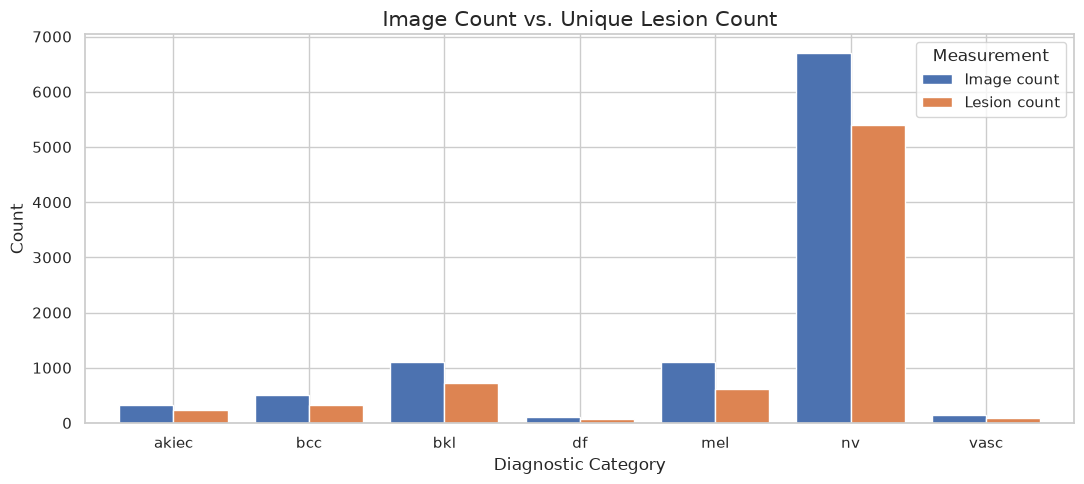

In [12]:
comparison.plot(
    kind="bar",
    figsize=(11, 5),
    width=0.8
)

plt.title("Image Count vs. Unique Lesion Count",
          fontsize=15)
plt.xlabel("Diagnostic Category")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.legend(title="Measurement")
plt.tight_layout()
plt.show()

Missing age values: 57


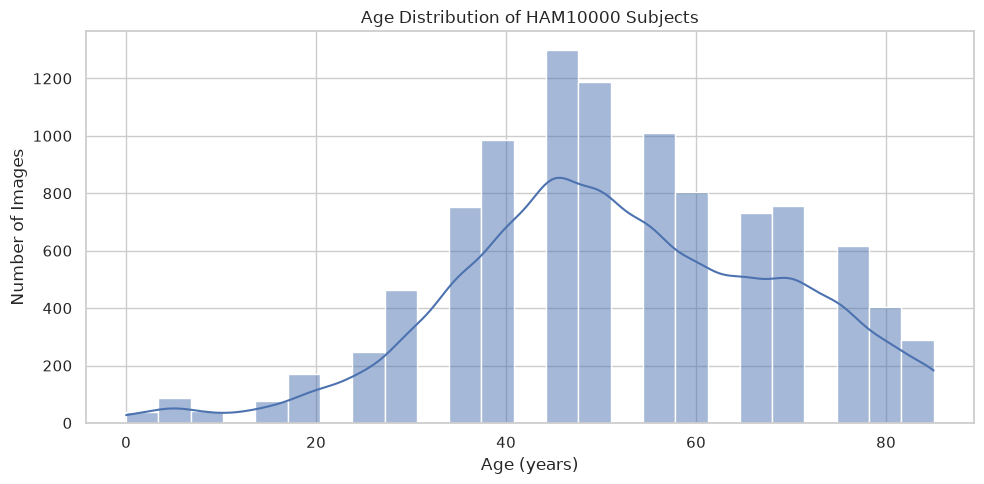

count    9958.00
mean       51.86
std        16.97
min         0.00
25%        40.00
50%        50.00
75%        65.00
max        85.00
Name: age, dtype: float64

In [13]:
print("Missing age values:", df["age"].isna().sum())

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="age",
    bins=25,
    kde=True
)

plt.title("Age Distribution of HAM10000 Subjects")
plt.xlabel("Age (years)")
plt.ylabel("Number of Images")

plt.tight_layout()
plt.show()

display(df["age"].describe().round(2))

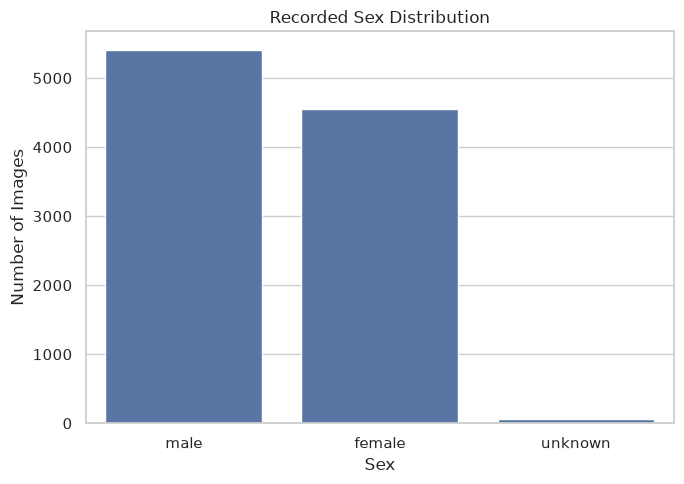

In [14]:
sex_counts = df["sex"].value_counts()

plt.figure(figsize=(7, 5))

sns.barplot(
    x=sex_counts.index,
    y=sex_counts.values
)

plt.title("Recorded Sex Distribution")
plt.xlabel("Sex")
plt.ylabel("Number of Images")

plt.tight_layout()
plt.show()

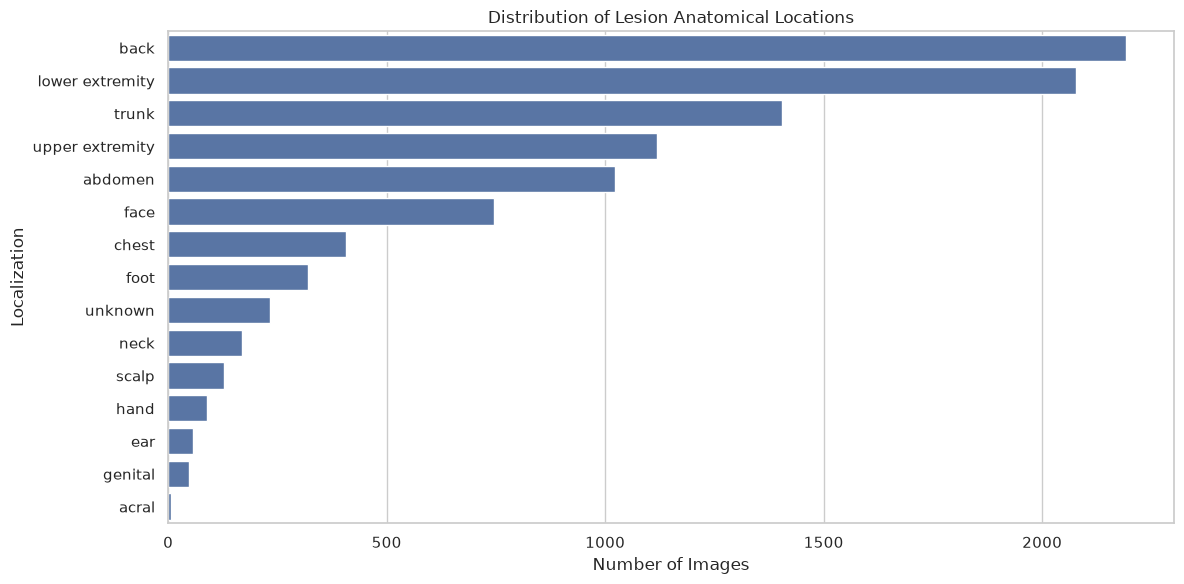

In [15]:
localization_counts = df["localization"].value_counts()

plt.figure(figsize=(12, 6))

sns.barplot(
    x=localization_counts.values,
    y=localization_counts.index
)

plt.title("Distribution of Lesion Anatomical Locations")
plt.xlabel("Number of Images")
plt.ylabel("Localization")

plt.tight_layout()
plt.show()

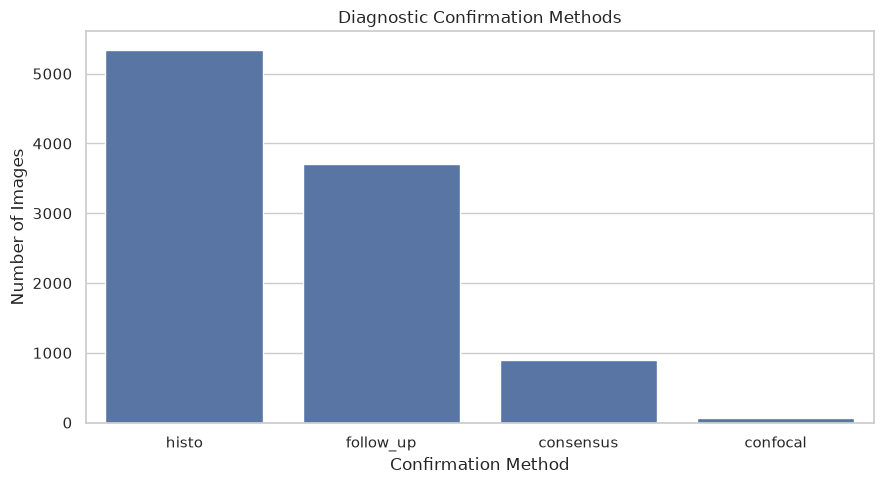

In [16]:
confirmation_counts = df["dx_type"].value_counts()

plt.figure(figsize=(9, 5))

sns.barplot(
    x=confirmation_counts.index,
    y=confirmation_counts.values
)

plt.title("Diagnostic Confirmation Methods")
plt.xlabel("Confirmation Method")
plt.ylabel("Number of Images")

plt.tight_layout()
plt.show()

In [17]:
confirmation_table = pd.crosstab(
    df["dx"],
    df["dx_type"]
)

display(confirmation_table)

dx_type,confocal,consensus,follow_up,histo
dx,,,,
akiec,0,0,0,327
bcc,0,0,0,514
bkl,69,264,0,766
df,0,60,0,55
mel,0,0,0,1113
nv,0,503,3704,2498
vasc,0,75,0,67


In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import random

PROJECT_ROOT = Path.cwd()

DATA_DIR = PROJECT_ROOT / "data" / "raw"

IMAGE_DIRS = [
    DATA_DIR / "HAM10000_images_part_1",
    DATA_DIR / "HAM10000_images_part_2",
]

METADATA_PATH = DATA_DIR / "HAM10000_metadata"

df = pd.read_csv(METADATA_PATH)

# Build an image ID -> file path mapping
image_paths = {}

for directory in IMAGE_DIRS:
    for path in directory.glob("*.jpg"):
        image_paths[path.stem] = path

# Attach image paths to the metadata
df["image_path"] = df["image_id"].map(image_paths)

print("Metadata records:", len(df))
print("Image paths found:", df["image_path"].notna().sum())

df.head()

Metadata records: 10015
Image paths found: 10015


,lesion_id,image_id,dx,dx_type,age,sex,localization,dataset,image_path
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,vidir_modern,/home/shishirdhar/Research/boundary-quantum-fi...
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,vidir_modern,/home/shishirdhar/Research/boundary-quantum-fi...
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,vidir_modern,/home/shishirdhar/Research/boundary-quantum-fi...
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,vidir_modern,/home/shishirdhar/Research/boundary-quantum-fi...
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,vidir_modern,/home/shishirdhar/Research/boundary-quantum-fi...


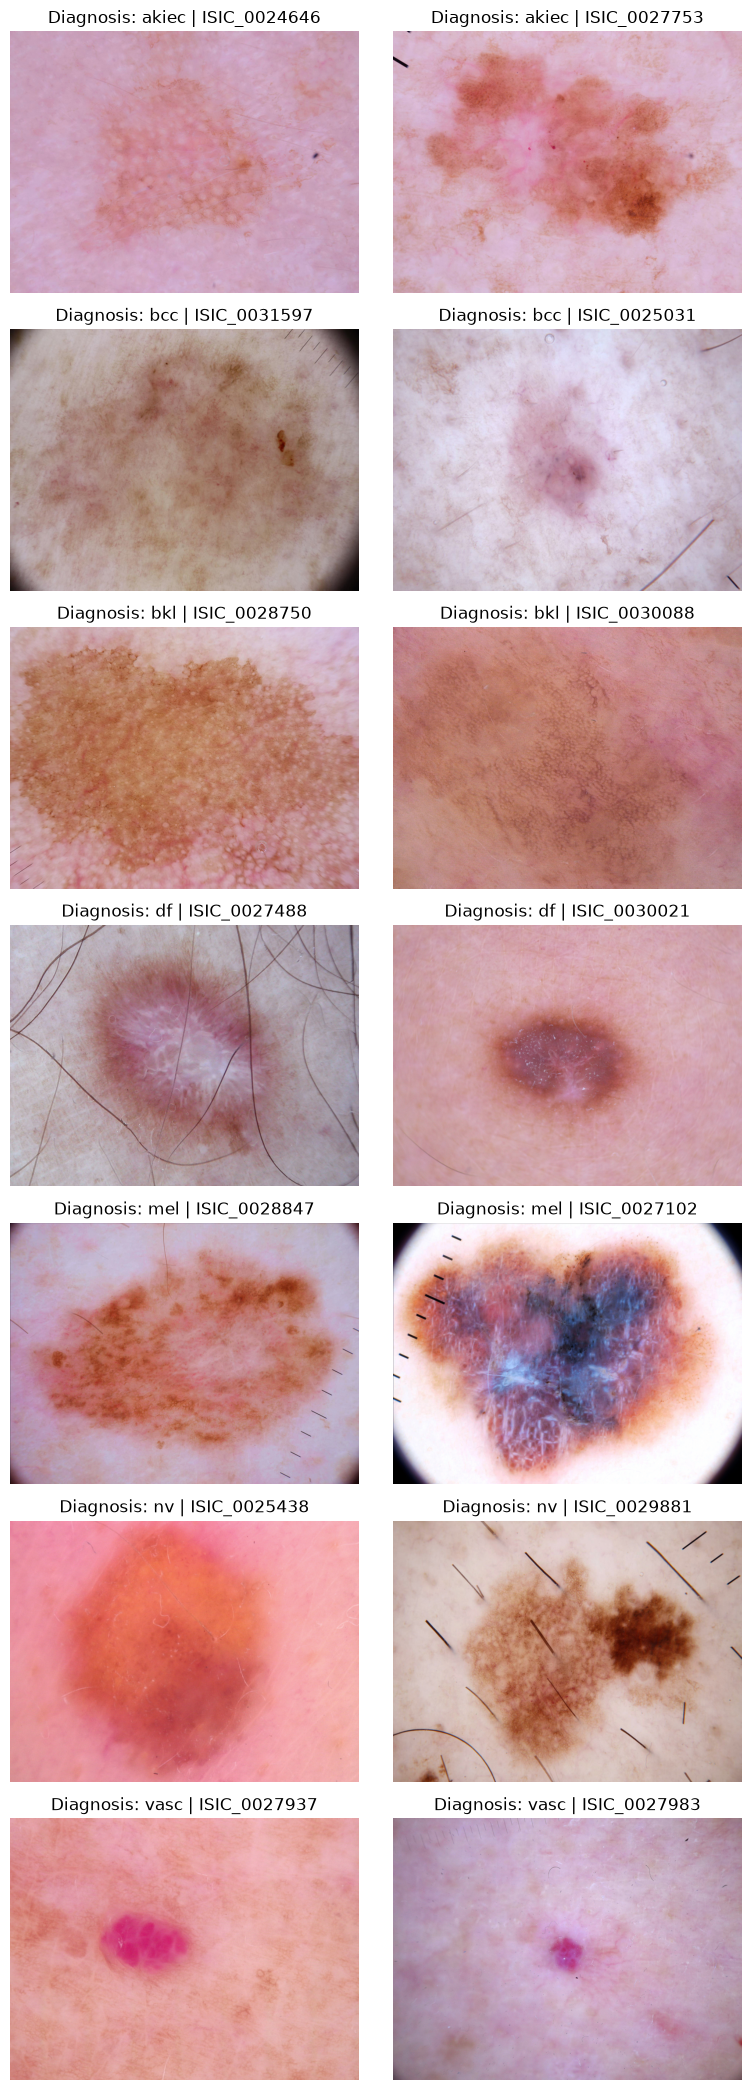

In [2]:
classes = sorted(df["dx"].unique())

fig, axes = plt.subplots(
    len(classes),
    2,
    figsize=(8, 3 * len(classes))
)

for row, diagnosis in enumerate(classes):

    samples = df[df["dx"] == diagnosis].sample(
        n=2,
        random_state=42
    )

    for col, (_, record) in enumerate(samples.iterrows()):

        image = Image.open(record["image_path"]).convert("RGB")

        axes[row, col].imshow(image)
        axes[row, col].set_title(
            f"Diagnosis: {diagnosis} | {record['image_id']}"
        )
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()